# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd

donnees_brutes = pd.read_csv("donnees/consommation_brut.csv")

print("Dimensions :", donnees_brutes.shape)
print("\nDtypes des colonnes :")
print(donnees_brutes.dtypes)
print("\nValeurs manquantes :")
print(donnees_brutes.isna().sum())
print("\nNombre de doublons :", donnees_brutes.duplicated().sum())

Dimensions : (300, 4)

Dtypes des colonnes :
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Nombre de doublons : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print("Nombre de graphies pour la colonne quartier :", donnees_brutes["quartier"].nunique())
print("\nToutes les valeurs observées :")
print(sorted(donnees_brutes["quartier"].unique()))

Nombre de graphies pour la colonne quartier : 43

Toutes les valeurs observées :
[' Bas-Peu-de-Chose', ' Carénage', ' Delmas 33', ' Delmas 65', ' Delmas 75', ' Morne Calvaire', ' Petite-Anse', ' Place Saint-Pierre', ' Thomassin', 'BAS-PEU-DE-CHOSE', 'BOIS-VERNA', 'Bas-Peu-de-Chose', 'Bas-Peu-de-Chose ', 'Bois-Verna', 'CARÉNAGE', 'CENTRE-VILLE', 'Carénage', 'Carénage ', 'Centre-ville', 'Centre-ville ', 'DELMAS 33', 'Delmas 33', 'Delmas 33 ', 'Delmas 65', 'Delmas 75', 'Delmas 75 ', 'Morne Calvaire', 'PLACE SAINT-PIERRE', 'Petite-Anse', 'Place Saint-Pierre', 'Place Saint-Pierre ', 'RUE 15', 'Rue 15', 'Rue 15 ', 'THOMASSIN', 'Thomassin', 'Thomassin ', 'bas-peu-de-chose', 'carénage', 'centre-ville', 'delmas 65', 'delmas 75', 'place saint-pierre']


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
colonne_kwh = donnees_brutes["kwh"]
conversion = pd.to_numeric(colonne_kwh, errors="coerce")

non_converties = colonne_kwh[conversion.isna() & colonne_kwh.notna()]
print("kwh qui ne sont pas des nombres valides :")
print(non_converties)

kwh qui ne sont pas des nombres valides :
0      184410 kWh
4      206280 kWh
9      215140 kWh
13        251 900
21     274520 kWh
27     301740 kWh
36     233010 kWh
43     155930 kWh
51     212510 kWh
53     424110 kWh
55     299610 kWh
58        373 880
59     333670 kWh
62     597730 kWh
66     456060 kWh
69     495020 kWh
72        409 300
82        556 070
88     260360 kWh
89     260360 kWh
104    347870 kWh
105       408 780
109       364 090
116    243160 kWh
138       154 720
139       154 720
154       233 700
171       253 300
182    385840 kWh
190    445270 kWh
194       337 810
195       366 390
204       154 740
207    170420 kWh
213    201690 kWh
214    201690 kWh
226     81370 kWh
228    139470 kWh
229     77670 kWh
230    139230 kWh
231    139230 kWh
235       121 240
237    160110 kWh
242       105 830
260    163010 kWh
264    198720 kWh
271       281 240
273       104 640
277    166700 kWh
284        73 110
292       171 160
297    187230 kWh
Name: kwh, dtype: str


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
donnees_propres = donnees_brutes.copy()

donnees_propres["kwh"] = donnees_propres["kwh"].str.replace(" kWh", "", regex=False).str.replace(" ", "", regex=False)
donnees_propres["kwh"] = pd.to_numeric(donnees_propres["kwh"], errors="coerce")

print("kwh manquants une fois convertis :", donnees_propres["kwh"].isna().sum())
print("Dtype de kwh :", donnees_propres["kwh"].dtype)

kwh manquants une fois convertis : 9
Dtype de kwh : float64


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
table_quartiers = pd.read_csv("donnees/quartiers.csv")

correspondance = {nom.lower(): nom for nom in table_quartiers["quartier"]}
donnees_propres["quartier"] = donnees_propres["quartier"].str.strip().str.lower().map(correspondance)

print("Nombre de quartiers uniques :", donnees_propres["quartier"].nunique())
print("Valeurs non mappées :", donnees_propres["quartier"].isna().sum())
print(sorted(donnees_propres["quartier"].dropna().unique()))

Nombre de quartiers uniques : 12
Valeurs non mappées : 0
['Bas-Peu-de-Chose', 'Bois-Verna', 'Carénage', 'Centre-ville', 'Delmas 33', 'Delmas 65', 'Delmas 75', 'Morne Calvaire', 'Petite-Anse', 'Place Saint-Pierre', 'Rue 15', 'Thomassin']


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
donnees_propres = donnees_propres.drop_duplicates()
donnees_propres = donnees_propres.dropna(subset=["kwh"])

print("Dimensions après nettoyage :", donnees_propres.shape)

Dimensions après nettoyage : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
for nom_quartier in donnees_propres["quartier"].unique():
    masque_quartier = donnees_propres["quartier"] == nom_quartier
    med = donnees_propres.loc[masque_quartier, "kwh"].median()
    aberrants = masque_quartier & (donnees_propres["kwh"] > 3 * med)
    nb = aberrants.sum()
    if nb > 0:
        print(f"{nom_quartier} : {nb} valeur(s) corrigée(s)")
    donnees_propres.loc[aberrants, "kwh"] = donnees_propres.loc[aberrants, "kwh"] / 10

print("\nValeur maximale de kwh :", donnees_propres["kwh"].max())

Delmas 33 : 1 valeur(s) corrigée(s)
Delmas 75 : 1 valeur(s) corrigée(s)
Morne Calvaire : 1 valeur(s) corrigée(s)
Rue 15 : 1 valeur(s) corrigée(s)

Valeur maximale de kwh : 742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
officiel = pd.read_csv("donnees/consommation.csv")

colonnes_cles = ["mois", "quartier", "kwh", "heures_courant"]

# On ne garde que les lignes communes avec donnees_propres
indices_communs = officiel.set_index(colonnes_cles).index.isin(
donnees_propres.set_index(colonnes_cles).index
)
officiel_aligné = officiel[indices_communs].reset_index(drop=True)

#Même ordre, même type kwh

donnees_propres = donnees_propres.sort_values(colonnes_cles).reset_index(drop=True)
officiel_aligné = officiel_aligné.sort_values(colonnes_cles).reset_index(drop=True)
officiel_aligné["kwh"] = officiel_aligné["kwh"].astype("float64")

print("Forme donnees_propres :", donnees_propres.shape)
print("Forme officiel aligné :", officiel_aligné.shape)
print("Le nettoyage correspond-il au fichier officiel ?",
    donnees_propres.equals(officiel_aligné[donnees_propres.columns]))

Forme donnees_propres : (279, 4)
Forme officiel aligné : (279, 5)
Le nettoyage correspond-il au fichier officiel ? True


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
print("Nombre de lignes avant merge :", donnees_propres.shape)

donnees_propres = donnees_propres.merge(table_quartiers, on="quartier", how="left")

donnees_propres["kwh_par_abonne"] = (donnees_propres["kwh"] / donnees_propres["abonnes"]).round(1)
donnees_propres["annee"] = donnees_propres["mois"].str[:4].astype(int)

print("Nombre de lignes après merge :", donnees_propres.shape)
print("\nDétail Bas-Peu-de-Chose / 2024-01 :")
print(donnees_propres.query("quartier == 'Bas-Peu-de-Chose' and mois == '2024-01'")[["quartier", "mois", "kwh", "abonnes", "kwh_par_abonne"]])

Nombre de lignes avant merge : (279, 4)
Nombre de lignes après merge : (279, 9)

Détail Bas-Peu-de-Chose / 2024-01 :
           quartier     mois       kwh  abonnes  kwh_par_abonne
0  Bas-Peu-de-Chose  2024-01  184410.0     2150            85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
donnees_meteo = pd.read_csv("donnees/meteo.csv")

print("Nombre de lignes avant merge météo :", donnees_propres.shape)

donnees_propres = donnees_propres.merge(donnees_meteo, on=["mois", "commune"], how="left")

print("Nombre de lignes après merge météo :", donnees_propres.shape)
print("Valeurs manquantes de température :", donnees_propres["temperature_c"].isna().sum())

Nombre de lignes avant merge météo : (279, 9)
Nombre de lignes après merge météo : (279, 11)
Valeurs manquantes de température : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
donnees_propres.to_csv("donnees/consommation_propre.csv", index=False)

relecture = pd.read_csv("donnees/consommation_propre.csv")
print("Dimensions du fichier propre relu :", relecture.shape)
print("Liste des colonnes :", list(relecture.columns))

Dimensions du fichier propre relu : (279, 11)
Liste des colonnes : ['mois', 'quartier', 'kwh', 'heures_courant', 'commune', 'type', 'abonnes', 'kwh_par_abonne', 'annee', 'temperature_c', 'pluie_mm']


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
moyenne_type = donnees_propres.groupby("type")["kwh_par_abonne"].mean().round(1)
print("kWh par abonné, moyenne par catégorie de quartier :")
print(moyenne_type)

print("\nTop des quartiers par kWh/abonné :")
top_quartiers = (
    donnees_propres.groupby("quartier")["kwh_par_abonne"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
)
print(top_quartiers)

kWh par abonné, moyenne par catégorie de quartier :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Top des quartiers par kWh/abonné :
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

Le type de quartier est déterminant : les commerciaux affichent en moyenne 393,2 kWh/abonné, soit près de 3,4 fois le niveau des résidentiels (117,4). Le trio de tête est Centre-ville (468,7), Place Saint-Pierre (458,3) et Delmas 33 (374,4) — tous commerciaux. La consommation par abonné reflète donc d'abord l'usage économique du quartier.

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

kWh totaux (millions) par commune :
annee            2024   2025  hausse_%
commune                               
Delmas          11.61  11.74       1.1
Port-au-Prince  10.09  10.31       2.3
Pétion-Ville     8.60   9.68      12.6
Cap-Haïtien      4.59   5.62      22.5


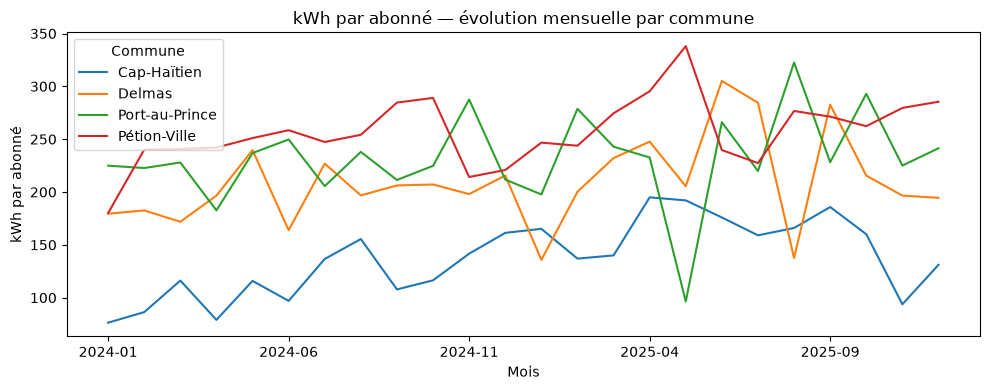

In [13]:
import matplotlib.pyplot as plt

# 1. Cumuls de consommation par commune et année
cumuls = donnees_propres.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
cumuls.columns = cumuls.columns.astype(str)

# 2. Taux de croissance (sur valeurs brutes)
cumuls["hausse_%"] = ((cumuls["2025"] / cumuls["2024"] - 1) * 100).round(1)

# 3. Vue en millions sans altérer la hausse
vue = cumuls.copy()
vue["2024"] = (vue["2024"] / 1_000_000).round(2)
vue["2025"] = (vue["2025"] / 1_000_000).round(2)
print("kWh totaux (millions) par commune :")
print(vue.sort_values("2025", ascending=False))

# 4. Courbes
courbes = donnees_propres.pivot_table(
    index="mois", columns="commune", values="kwh_par_abonne", aggfunc="mean"
)
ax = courbes.plot(kind="line", figsize=(10, 4))
ax.set_title("kWh par abonné — évolution mensuelle par commune")
ax.set_xlabel("Mois")
ax.set_ylabel("kWh par abonné")
ax.legend(title="Commune")
plt.tight_layout()
plt.show()

**Ce qu'on en conclut :**

Entre 2024 et 2025, la consommation progresse dans les quatre communes, mais de façon contrastée : Cap-Haïtien enregistre la plus forte croissance (+22,5 %, passant de 4,59 à 5,62 millions de kWh), alors que Delmas reste quasi stable (+1,1 %). Toutes suivent une saisonnalité similaire sur la courbe mensuelle, avec un pic en mai-juin et un creux en juillet-août.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

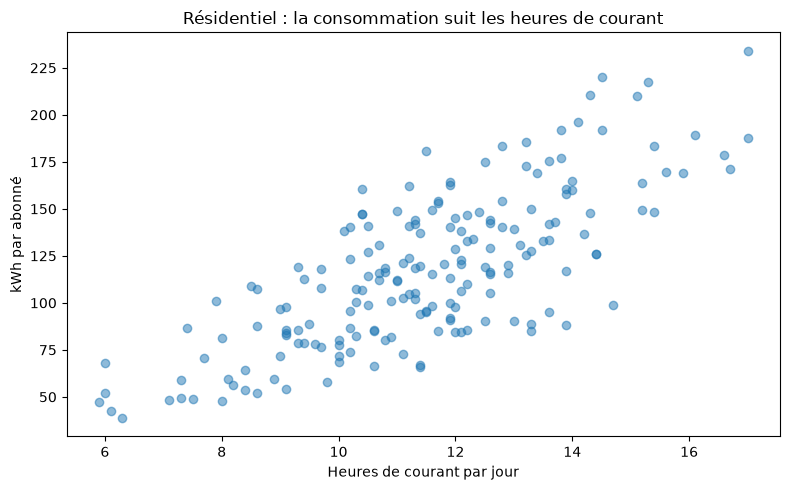

Corrélation kWh/abonné ↔ heures de courant : 0.76
Corrélation kWh/abonné ↔ température       : -0.15


In [14]:
import matplotlib.pyplot as plt

residences = donnees_propres[donnees_propres["type"] == "Résidentiel"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(residences["heures_courant"], residences["kwh_par_abonne"], alpha=0.5)
ax.set_title("Résidentiel : la consommation suit les heures de courant")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("kWh par abonné")
plt.tight_layout()
plt.show()

r_courant = residences["kwh_par_abonne"].corr(residences["heures_courant"])
r_chaleur = residences["kwh_par_abonne"].corr(residences["temperature_c"])

print(f"Corrélation kWh/abonné ↔ heures de courant : {r_courant:.2f}")
print(f"Corrélation kWh/abonné ↔ température       : {r_chaleur:.2f}")

**Ce qu'on en conclut :**

Chez les résidentiels, la corrélation entre consommation par abonné et heures de courant atteint 0,76 (forte), tandis que celle avec la température est de -0,15 (quasi nulle). Le message est clair : la consommation dépend de l'électricité disponible, pas du thermomètre. Le nuage de points confirme visuellement cette tendance.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

Statistiques des heures de courant par commune :
                mediane    q1    q3
commune                            
Cap-Haïtien        10.0   8.3  11.7
Delmas             11.9  10.1  13.0
Port-au-Prince     11.6  10.7  13.1
Pétion-Ville       11.6  10.4  13.0


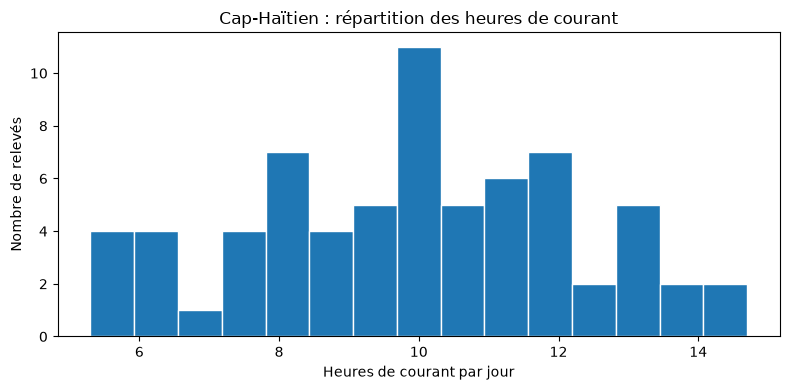

Nombre de relevés 2025 avec < 8h de courant : 3
        mois   quartier      commune  heures_courant
145  2025-01  Delmas 33       Delmas             7.4
222  2025-08   Carénage  Cap-Haïtien             7.3
265  2025-11     Rue 15  Cap-Haïtien             5.9


In [15]:
import matplotlib.pyplot as plt

# 1. Statistiques par commune
resume = donnees_propres.groupby("commune")["heures_courant"].agg(
    mediane="median",
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
).round(1)
print("Statistiques des heures de courant par commune :")
print(resume)

# 2. Histogramme Cap-Haïtien
cap_ha = donnees_propres[donnees_propres["commune"] == "Cap-Haïtien"]["heures_courant"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cap_ha, bins=15, edgecolor="white")
ax.set_title("Cap-Haïtien : répartition des heures de courant")
ax.set_xlabel("Heures de courant par jour")
ax.set_ylabel("Nombre de relevés")
plt.tight_layout()
plt.show()

# 3. Relevés de 2025 sous le seuil de 8h
sous_seuil = donnees_propres[(donnees_propres["annee"] == 2025) & (donnees_propres["heures_courant"] < 8)]
print("Nombre de relevés 2025 avec < 8h de courant :", len(sous_seuil))
print(sous_seuil[["mois", "quartier", "commune", "heures_courant"]])

**Ce qu'on en conclut :**

Cap-Haïtien est la commune la plus pénalisée : médiane de 10,0 heures de courant par jour, contre 11,6 à 11,9 ailleurs. En 2025, seuls 3 relevés tombent sous le seuil de 8 heures, dans les quartiers Carénage, Delmas 33 et Rue 15. Ces coupures prolongées pèsent logiquement sur la consommation moyenne par abonné.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
trois_plus_gros = donnees_propres.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]
print("Top 3 des consommations les plus élevées :")
print(trois_plus_gros)

Top 3 des consommations les plus élevées :
        mois      quartier        type       kwh
213  2025-07     Delmas 33  Commercial  742780.0
121  2024-11  Centre-ville  Commercial  597730.0
235  2025-09     Delmas 33  Commercial  591420.0


**Ce qu'on en conclut :**

Le top 3 des consommations les plus élevées est occupé par Delmas 33 (2025-07 : 742 780 kWh ; 2025-09 : 591 420 kWh) et Centre-ville (2024-11 : 597 730 kWh). Les trois sont des quartiers commerciaux, ce qui explique ces volumes. Aucun ne dépasse 3 fois la médiane de son quartier : ce ne sont pas des valeurs aberrantes mais des pics d'activité.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

Dans le résidentiel, c'est le courant disponible qui fait la consommation (corrélation 0,76), pas la chaleur (-0,15) : on consomme ce qu'on reçoit. Cap-Haïtien combine la plus forte hausse (+22,5 % sur l'année) et les coupures les plus longues (10,0 heures de médiane). Attention : une corrélation n'est pas une cause — il faudrait des données individuelles par abonné et des périodes sans coupure pour isoler l'effet de la température.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.